In [6]:
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, LSTM, GRU, Dense
import matplotlib.pyplot as plt

num_words = 10000
max_sequence_length = 500
(x_train, y_train), (x_test, y_test) = imdb.load_data(num_words=num_words)

x_train = pad_sequences(x_train, maxlen=max_sequence_length)
x_test = pad_sequences(x_test, maxlen=max_sequence_length)

model_names = ['SimpleRNN', 'LSTM', 'GRU']
layers = [SimpleRNN, LSTM, GRU]


In [7]:
def build_model(layer_type):

    num_words = 10000
    max_sequence_length = 500
    embedding_dim = 32

    model = Sequential([
        Embedding(input_dim=num_words, output_dim=embedding_dim, input_length=max_sequence_length),
        layer_type(32),
        Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model

In [8]:
def run_models(model_names, layers, x_train, y_train, x_test, y_test):
    histories, test_losses, test_accuracies = [], [], []

    for model_name, layer in zip(model_names, layers):
        print(f"\nTraining {model_name}...")
        model = build_model(layer)

        history = model.fit(
            x_train, y_train,
            epochs=10,
            batch_size=64,
            validation_split=0.2,
            verbose=1
        )

In [17]:
def run_models(model_names, layers, x_train, y_train, x_test, y_test):
    histories, test_losses, test_accuracies = [], [], []

    for model_name, layer in zip(model_names, layers):
        print(f"\nTraining {model_name}...")
        model = build_model(layer)

        history = model.fit(
            x_train, y_train,
            epochs=10,
            batch_size=64,
            validation_split=0.2,
            verbose=1
        )

        histories.append(history)

        test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)
        test_losses.append(test_loss)
        test_accuracies.append(test_accuracy)

        print(f'{model_name} Test loss: {test_loss:.4f}, Test accuracy: {test_accuracy:.4f}')
    return test_losses, test_accuracies


test_losses, test_accuracies = run_models(model_names, layers, x_train, y_train, x_test, y_test)


Training SimpleRNN...
Epoch 1/10


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


313/313 ━━━━━━━━━━━━━━━━━━━━ 16s 40ms/step - accuracy: 0.5673 - loss: 0.6682 - val_accuracy: 0.8072 - val_loss: 0.4330
Epoch 2/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 11s 36ms/step - accuracy: 0.8434 - loss: 0.3668 - val_accuracy: 0.8406 - val_loss: 0.3805
Epoch 3/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 11s 34ms/step - accuracy: 0.8358 - loss: 0.3686 - val_accuracy: 0.8310 - val_loss: 0.4110
Epoch 4/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 11s 35ms/step - accuracy: 0.9190 - loss: 0.2130 - val_accuracy: 0.8494 - val_loss: 0.3764
Epoch 5/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 11s 35ms/step - accuracy: 0.9532 - loss: 0.1323 - val_accuracy: 0.8332 - val_loss: 0.4572
Epoch 6/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 11s 35ms/step - accuracy: 0.9776 - loss: 0.0718 - val_accuracy: 0.7986 - val_loss: 0.5803
Epoch 7/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 11s 35ms/step - accuracy: 0.9792 - loss: 0.0628 - val_accuracy: 0.8040 - val_loss: 0.6404
Epoch 8/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 11s 34ms/step - accuracy: 0.9880 - loss: 0.0417 - val_accurac

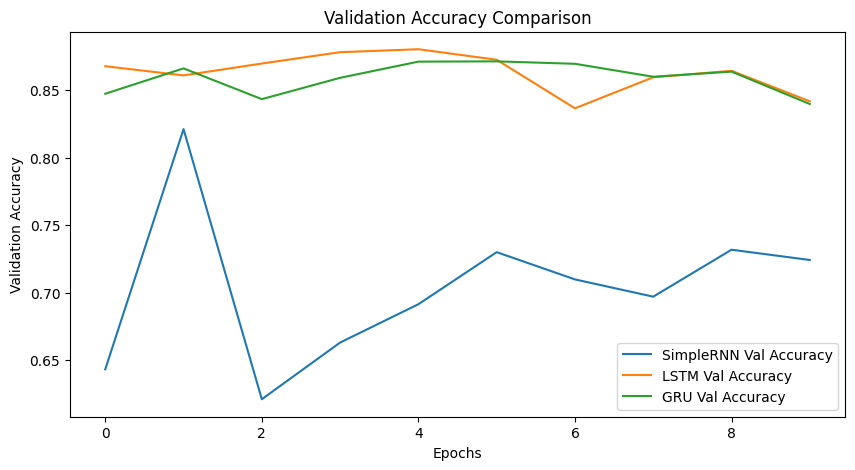

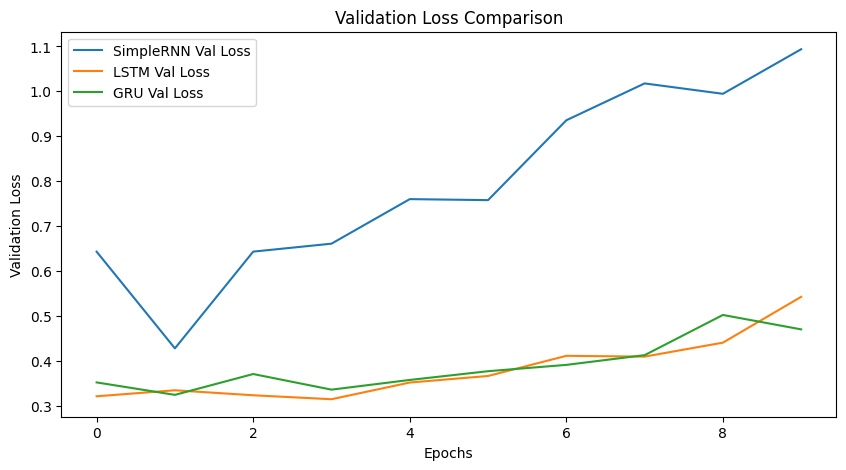

In [18]:
plt.figure(figsize=(10, 5))
for model_name, history in zip(model_names, histories):
      plt.plot(history.history['val_accuracy'], label=f'{model_name} Val Accuracy')
plt.title('Validation Accuracy Comparison')
plt.xlabel('Epochs')
plt.ylabel('Validation Accuracy')
plt.legend()
plt.show()

plt.figure(figsize=(10, 5))
for model_name, history in zip(model_names, histories):
   plt.plot(history.history['val_loss'], label=f'{model_name} Val Loss')
plt.title('Validation Loss Comparison')
plt.xlabel('Epochs')
plt.ylabel('Validation Loss')
plt.legend()
plt.show()